2025-07-24 17:21:55.983797: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753377716.214646      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753377716.283593      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753379704.576399      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753379704.577097      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753379710.160374     105 service.cc:148] XLA service 0x79ffb0006930 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753379710.161212     105 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1753379710.161232     105 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1753379710.413330     105 cuda_dnn.cc:529] Loaded cuDNN version 90300


  18/2539 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.5157 - loss: 0.7037

I0000 00:00:1753379712.394093     105 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2539/2539 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - accuracy: 0.5274 - loss: 0.6913 - val_accuracy: 0.6854 - val_loss: 0.6156
Epoch 2/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6329 - loss: 0.6426 - val_accuracy: 0.7131 - val_loss: 0.5739
Epoch 3/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6853 - loss: 0.5949 - val_accuracy: 0.7633 - val_loss: 0.5254
Epoch 4/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6966 - loss: 0.5782 - val_accuracy: 0.7596 - val_loss: 0.5241
Epoch 5/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7071 - loss: 0.5658 - val_accuracy: 0.7151 - val_loss: 0.5619
Epoch 6/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7129 - loss: 0.5602 - val_accuracy: 0.7833 - val_loss: 0.4995
Epoch 7/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7143 - loss: 0.5564 - val_accuracy: 0.7476 - val_loss: 0.5251
Epoch 8/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7135 - loss: 0.55

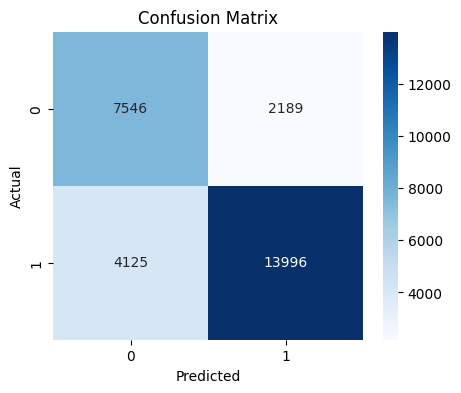


Classification Report:
               precision    recall  f1-score   support

           0     0.6466    0.7751    0.7050      9735
           1     0.8648    0.7724    0.8160     18121

    accuracy                         0.7733     27856
   macro avg     0.7557    0.7738    0.7605     27856
weighted avg     0.7885    0.7733    0.7772     27856

Sensitivity (Recall): 0.7724
Specificity: 0.7751


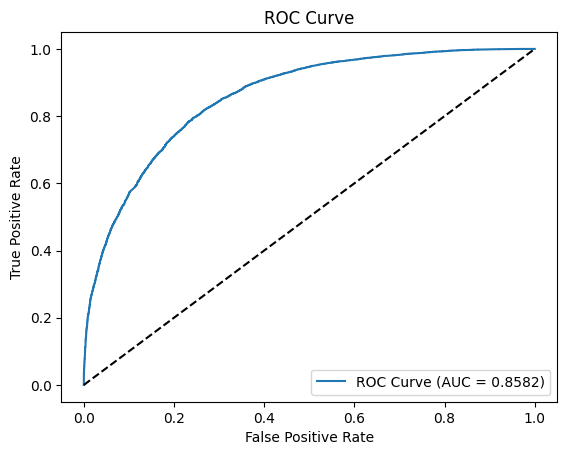

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, GlobalMaxPooling1D, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert strings to array safely
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🔁 Step 6: Reshape for CNN input
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# 🧠 Step 7: CNN Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the Model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64)

# 📊 Step 9: Evaluate the Model
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()
